# Video Game Sales Analysis 🎮


This project explores video game sales trends, regional preferences, review scores, and statistical hypotheses to support a hypothetical marketing strategy for 2017.

**Research question:** Which platforms, genres, and regional markets show the most promising commercial potential based on the available historical data?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_ind

In [2]:
games = pd.read_csv('data/games.csv')

### Initial Data Exploration

In [3]:
games.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [5]:
games.describe()

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


In [6]:
games.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

In [7]:
games.duplicated().sum()

np.int64(0)

- Missing values are present in `year_of_release`, `critic_score`, `user_score`, and `rating`.
- The `user_score` column needs to be converted to a numeric data type.

### Data Preparation

In [8]:
games.columns = games.columns.str.lower()

In [9]:
games['year_of_release'] = games['year_of_release'].astype('Int64')

In [10]:
games['user_score'].unique()

array(['8', nan, '8.3', '8.5', '6.6', '8.4', '8.6', '7.7', '6.3', '7.4',
       '8.2', '9', '7.9', '8.1', '8.7', '7.1', '3.4', '5.3', '4.8', '3.2',
       '8.9', '6.4', '7.8', '7.5', '2.6', '7.2', '9.2', '7', '7.3', '4.3',
       '7.6', '5.7', '5', '9.1', '6.5', 'tbd', '8.8', '6.9', '9.4', '6.8',
       '6.1', '6.7', '5.4', '4', '4.9', '4.5', '9.3', '6.2', '4.2', '6',
       '3.7', '4.1', '5.8', '5.6', '5.5', '4.4', '4.6', '5.9', '3.9',
       '3.1', '2.9', '5.2', '3.3', '4.7', '5.1', '3.5', '2.5', '1.9', '3',
       '2.7', '2.2', '2', '9.5', '2.1', '3.6', '2.8', '1.8', '3.8', '0',
       '1.6', '9.6', '2.4', '1.7', '1.1', '0.3', '1.5', '0.7', '1.2',
       '2.3', '0.5', '1.3', '0.2', '0.6', '1.4', '0.9', '1', '9.7'],
      dtype=object)

In [11]:
games['user_score'] = games['user_score'].replace('tbd', np.nan)

In [12]:
games['user_score'] = games['user_score'].astype(float)

In [13]:
games.isna().sum()

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64

- **`name` and `genre`:** Without a game title, the record cannot be analyzed meaningfully, so we remove the two rows with missing names. Missing genre values can remain as `NaN`.
- **`year_of_release`:** There is no reliable basis for estimating missing release years, so we retain them as `NaN`.
- **`critic_score`, `user_score`, and `rating`:** Imputing review scores or age ratings would not be justified, so we leave missing values as `NaN`.

In [14]:
games = games.dropna(subset=['name'])

In [15]:
games['total_sales'] = (games['na_sales'] + games['eu_sales'] + games['jp_sales'] + games['other_sales'])

### Exploratory Data Analysis

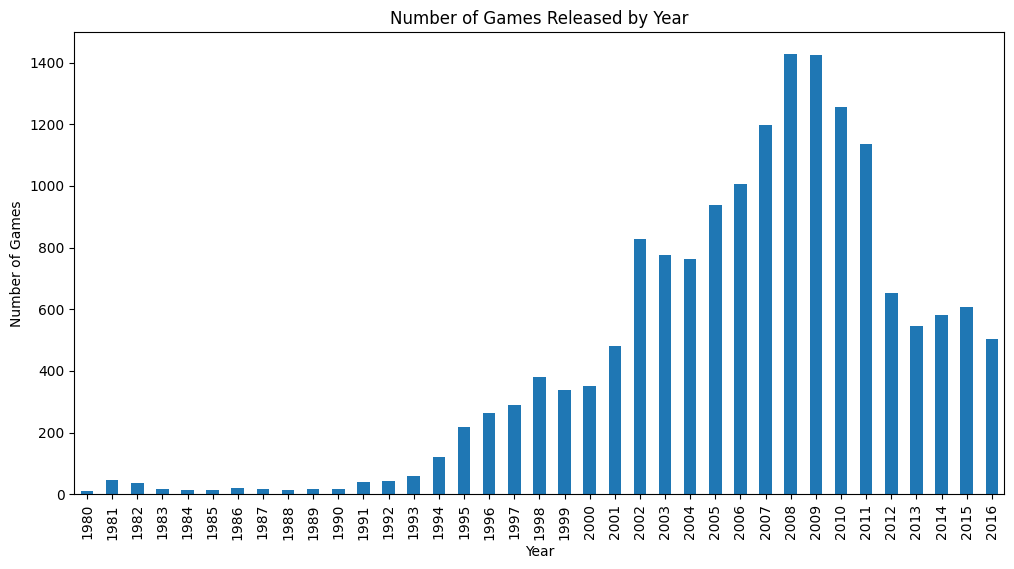

In [16]:
games_per_year = games['year_of_release'].value_counts().sort_index()

games_per_year.plot(kind='bar', figsize=(12,6))

plt.title('Number of Games Released by Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')

plt.show()

- Relatively few games were released annually before the early 1990s.
- Annual releases increased substantially between 1994 and 2008.
- The dataset peaks around 2008–2009, at approximately 1,400 releases per year.
- The number of releases then declines. Keep in mind that the final year, 2016, may have incomplete data.

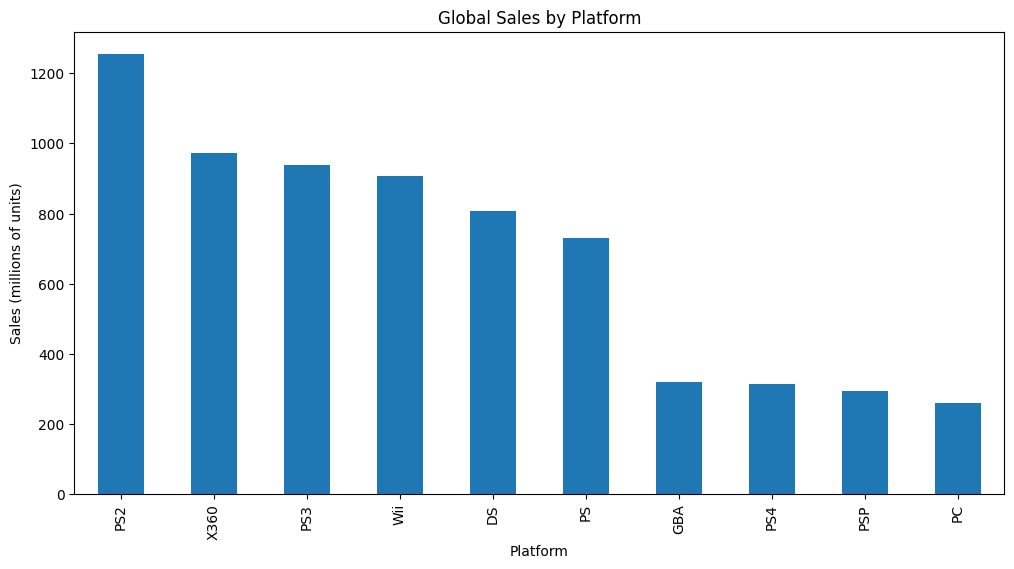

In [17]:
platform_sales = (games.groupby('platform')['total_sales'].sum().sort_values(ascending=False))

top_platforms = platform_sales.head(10)

top_platforms.plot(kind='bar', figsize=(12,6))

plt.title('Global Sales by Platform')
plt.xlabel('Platform')
plt.ylabel('Sales (millions of units)')

plt.show()

- PS2 has the highest cumulative global sales, followed by Xbox 360, PS3, Wii, DS, and the original PlayStation.
- However, to understand potential opportunities for 2017, we also need to examine how sales changed year by year.

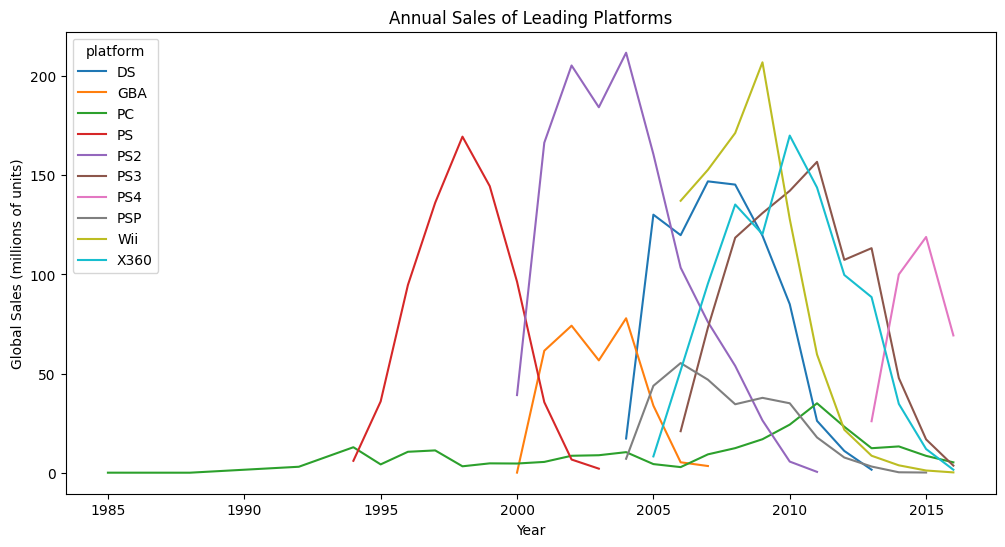

In [18]:
top_platforms = platform_sales.head(10).index

platform_year = (games[games['platform'].isin(top_platforms)].pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum'))

platform_year.plot(figsize=(12,6))

plt.title('Annual Sales of Leading Platforms')
plt.xlabel('Year')
plt.ylabel('Global Sales (millions of units)')

plt.show()

- Major platforms tend to follow similar lifecycles: sales grow, peak, and decline as the platform is gradually replaced.
- In this sample, these cycles typically span around 8–10 years.
- PS2, DS, Wii, and PSP all experienced strong sales before becoming much less commercially relevant.
- This reflects how new console generations gradually replace older ones.
- Since older data describe a different market environment, we focus on the more recent period (2012 onward) for the 2017 planning scenario.

In [19]:
games_recent = games[games['year_of_release'] >= 2012]

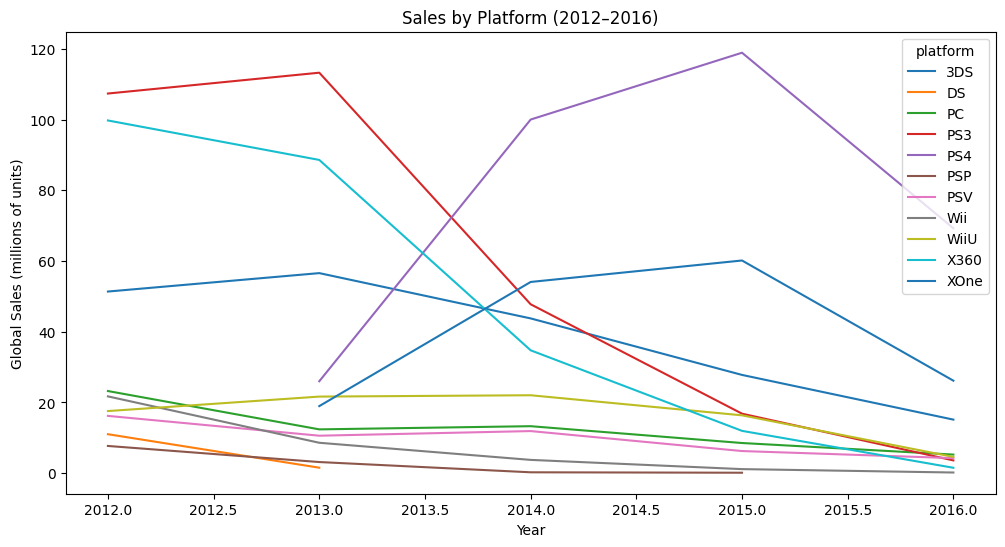

In [20]:
platform_recent = (games_recent.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum'))

platform_recent.plot(figsize=(12,6))

plt.title('Sales by Platform (2012–2016)')
plt.xlabel('Year')
plt.ylabel('Global Sales (millions of units)')

plt.show()

- The recent data show a clear shift in platform leadership.
- PS4 and Xbox One represent the newer console generation and stand out as promising targets for 2017 campaigns.
- PS3 and Xbox 360 show sustained declines, suggesting their lifecycles are approaching an end.
- Wii U, PS Vita, and 3DS remain active but generate considerably lower sales.
- Based on these patterns, PS4 and Xbox One appear to offer the strongest opportunities for future campaigns.

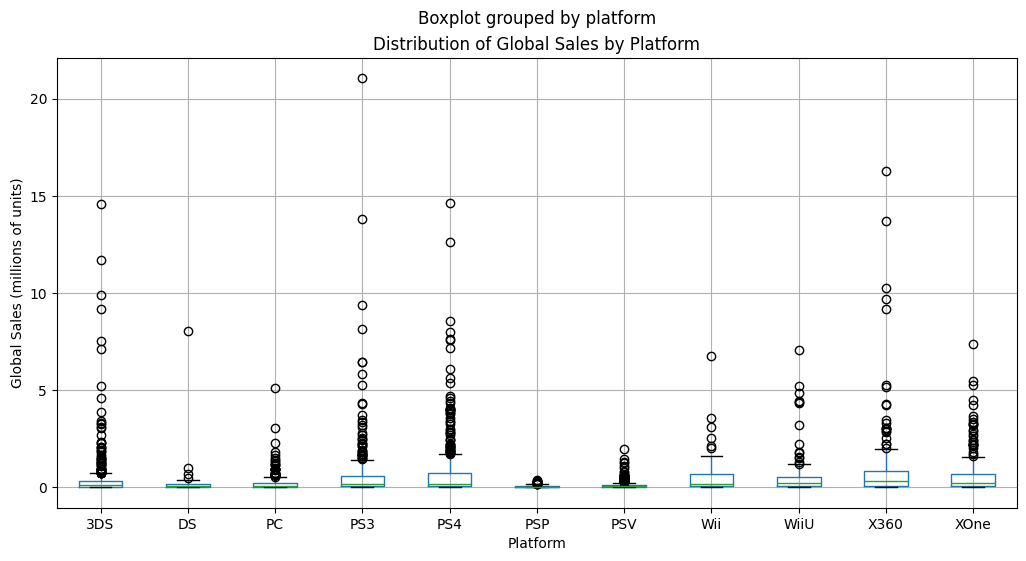

In [21]:
games_recent.boxplot(column='total_sales', by='platform', figsize=(12, 6))

plt.title('Distribution of Global Sales by Platform')
plt.xlabel('Platform')
plt.ylabel('Global Sales (millions of units)')

plt.show()

- Most titles have relatively low sales regardless of platform.
- The distributions contain many outliers: a small number of hit games sell far more than the typical title, which is common in the video game industry.
- PS4 and Xbox One show somewhat stronger sales distributions, but the differences between platforms are not dramatic; low-selling games are common everywhere.

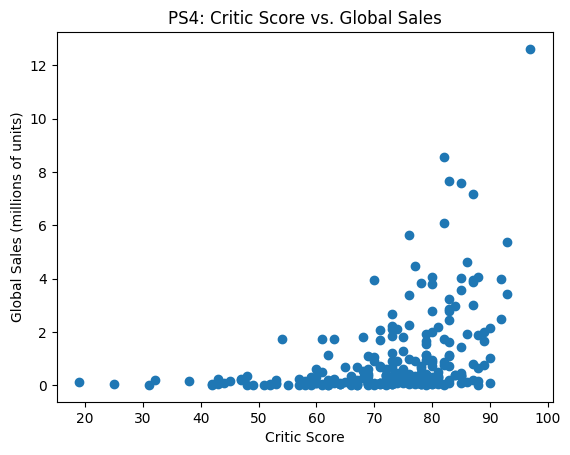

In [22]:
ps4 = games_recent[games_recent['platform'] == 'PS4']

plt.scatter(ps4['critic_score'], ps4['total_sales'])

plt.title('PS4: Critic Score vs. Global Sales')
plt.xlabel('Critic Score')
plt.ylabel('Global Sales (millions of units)')

plt.show()

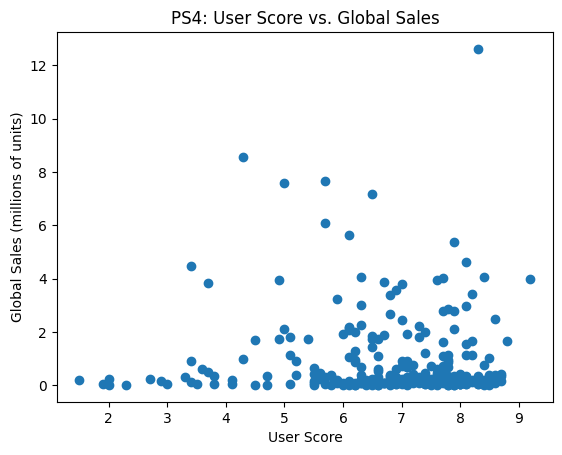

In [23]:
ps4 = games_recent[games_recent['platform'] == 'PS4']

plt.scatter(ps4['user_score'], ps4['total_sales'])

plt.title('PS4: User Score vs. Global Sales')
plt.xlabel('User Score')
plt.ylabel('Global Sales (millions of units)')

plt.show()

In [24]:
print('Correlation Between Critic Score and Total Sales:')
ps4['critic_score'].corr(ps4['total_sales'])

Correlation Between Critic Score and Total Sales:


np.float64(0.40656790206178095)

In [25]:
print('Correlation Between User Score and Total Sales:')
ps4['user_score'].corr(ps4['total_sales'])

Correlation Between User Score and Total Sales:


np.float64(-0.031957110204556376)

- Critic scores show a moderate positive correlation (approximately **0.41**) with global sales of PS4 games.
- Higher-rated games therefore tend to sell more in this sample, although many other factors also influence sales.
- User scores, by contrast, show almost no linear correlation with sales (approximately **−0.03**).
- For PS4, user ratings do not appear to be a useful linear indicator of sales.
- Overall, critic scores are more informative about sales than user scores in this analysis. These are associations, not evidence of causation.

In [26]:
top_games = ps4.sort_values(by='total_sales', ascending=False).head(10)

top_games[['name', 'total_sales']]

,name,total_sales
31,Call of Duty: Black Ops 3,14.63
42,Grand Theft Auto V,12.62
77,FIFA 16,8.58
87,Star Wars Battlefront (2015),7.98
92,Call of Duty: Advanced Warfare,7.66
94,FIFA 17,7.60
105,Fallout 4,7.17
143,FIFA 15,6.08
154,Destiny,5.64
171,Uncharted 4: A Thief's End,5.39


In [27]:
games[games['name'] == 'Call of Duty: Black Ops 3'][['name', 'platform', 'total_sales']].sort_values(by='total_sales', ascending=False)

,name,platform,total_sales
31,Call of Duty: Black Ops 3,PS4,14.63
99,Call of Duty: Black Ops 3,XOne,7.39
1049,Call of Duty: Black Ops 3,X360,1.70
1062,Call of Duty: Black Ops 3,PS3,1.69
6463,Call of Duty: Black Ops 3,PC,0.26


In [28]:
games[games['name'] == 'Grand Theft Auto V'][['name', 'platform', 'total_sales']].sort_values(by='total_sales', ascending=False)

,name,platform,total_sales
16,Grand Theft Auto V,PS3,21.05
23,Grand Theft Auto V,X360,16.27
42,Grand Theft Auto V,PS4,12.62
165,Grand Theft Auto V,XOne,5.47
1730,Grand Theft Auto V,PC,1.17


In [29]:
games[games['name'] == 'FIFA 16'][['name', 'platform', 'total_sales']].sort_values(by='total_sales', ascending=False)

,name,platform,total_sales
77,FIFA 16,PS4,8.58
417,FIFA 16,XOne,3.25
552,FIFA 16,PS3,2.70
1182,FIFA 16,X360,1.57
7575,FIFA 16,PC,0.20


- Comparing the same titles across platforms shows that successful games often sell well on several consoles, although sales volumes can differ substantially.
- *Call of Duty: Black Ops III* and *FIFA 16* sold more on PS4 in the comparisons examined.
- *Grand Theft Auto V* sold more on PS3 and Xbox 360, reflecting the platforms that were established when the game launched.
- Larger installed player bases and platform popularity may help explain differences in sales for the same game.

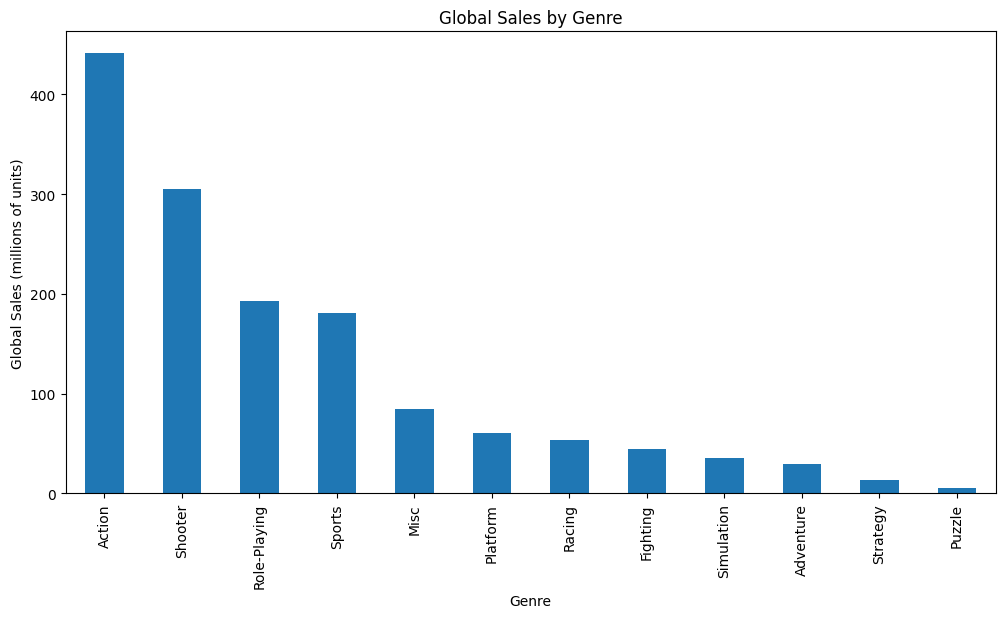

In [30]:
genre_sales = (games_recent.groupby('genre')['total_sales'].sum().sort_values(ascending=False))

genre_sales.plot(kind='bar', figsize=(12,6))

plt.title('Global Sales by Genre')
plt.xlabel('Genre')
plt.ylabel('Global Sales (millions of units)')

plt.show()

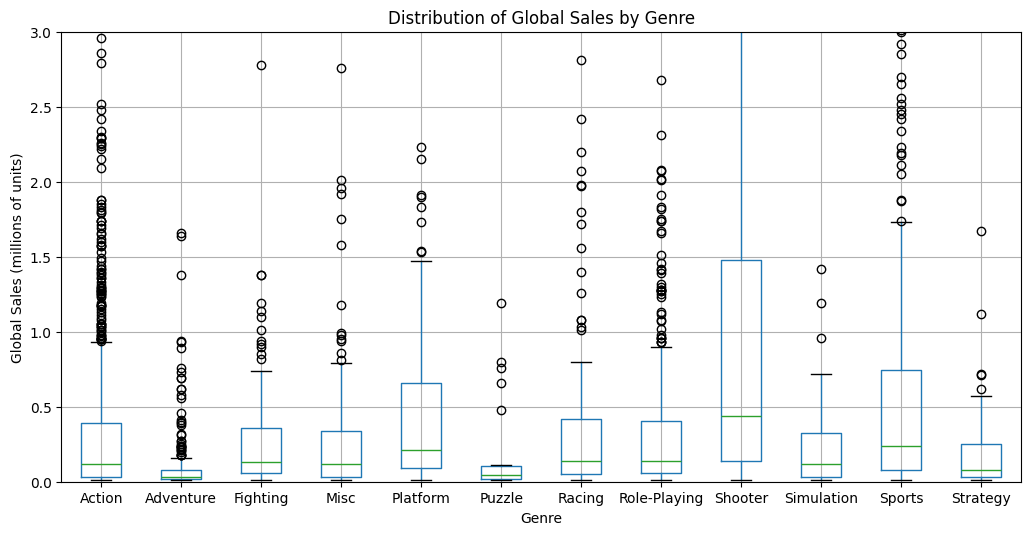

In [31]:
games_recent.boxplot(column='total_sales', by='genre', figsize=(12,6))

plt.ylim(0,3)

plt.title('Distribution of Global Sales by Genre')
plt.suptitle('')
plt.xlabel('Genre')
plt.ylabel('Global Sales (millions of units)')

plt.show()

- Action has the highest total global sales, followed by Shooter, Role-Playing, and Sports. These genres account for a substantial share of the market's sales.
- Shooter has a higher median in the boxplot, suggesting stronger sales for a typical title in that genre.
- Action includes many outliers—major hits that push up its overall sales volume.
- Adventure, Puzzle, and Strategy generally show lower per-game sales.
- Overall, Action, Shooter, Role-Playing, and Sports appear to have the strongest commercial potential in this sample.

## Regional Market Profiles

### Top Five Platforms by Region

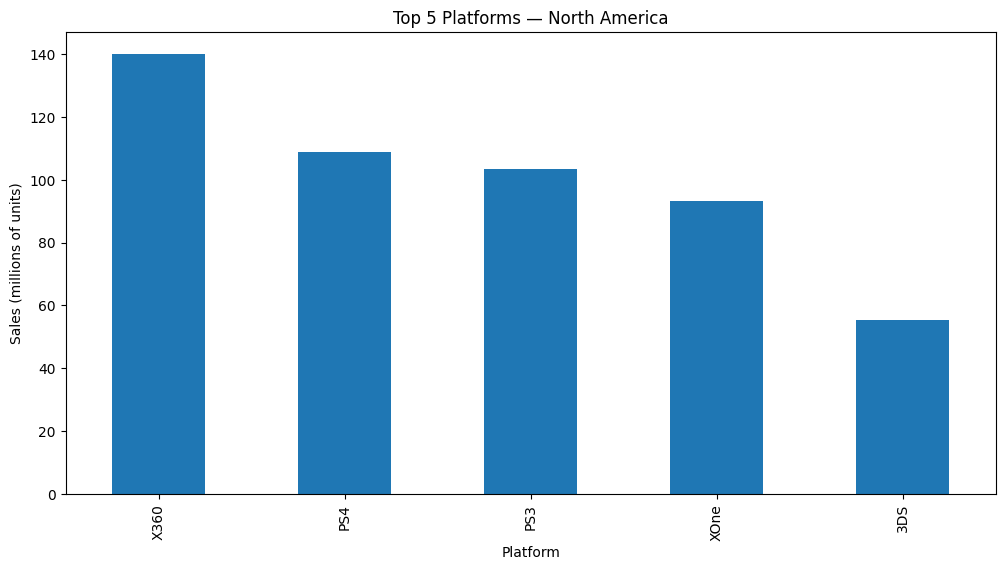

In [32]:
na_platform = games_recent.groupby('platform')['na_sales'].sum().sort_values(ascending=False)

na_platform.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Platforms — North America')
plt.xlabel('Platform')
plt.ylabel('Sales (millions of units)')

plt.show()

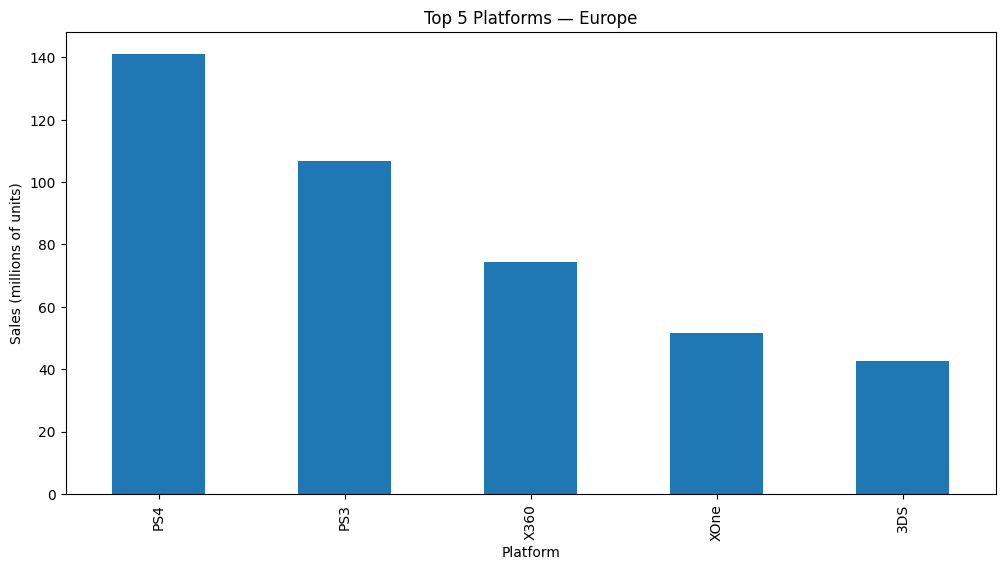

In [33]:
eu_platform = games_recent.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)

eu_platform.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Platforms — Europe')
plt.xlabel('Platform')
plt.ylabel('Sales (millions of units)')

plt.show()

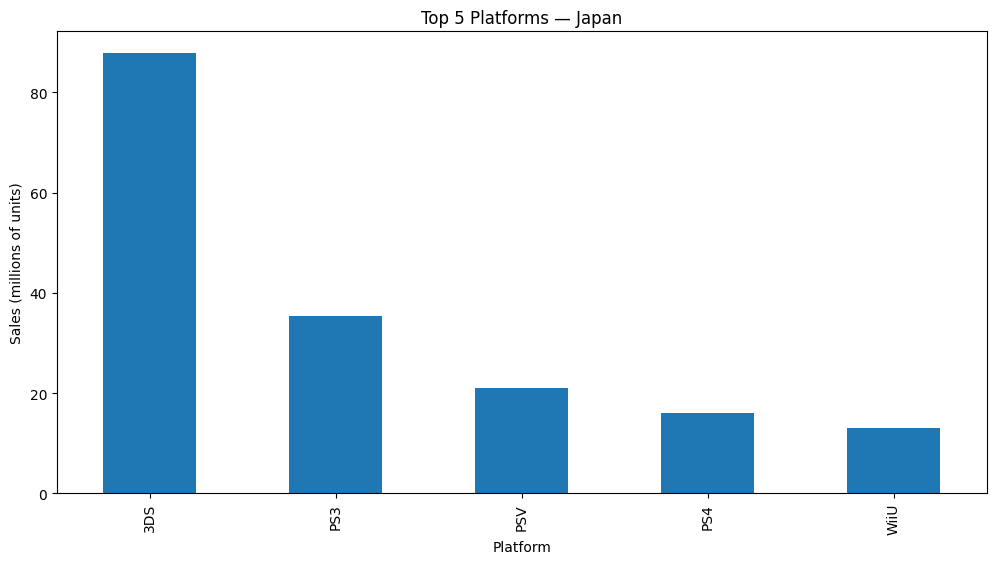

In [34]:
jp_platform = games_recent.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)

jp_platform.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Platforms — Japan')
plt.xlabel('Platform')
plt.ylabel('Sales (millions of units)')

plt.show()

- Platform preferences vary substantially across regions.
- In North America, Xbox 360 leads, followed by PS4, PS3, and Xbox One.
- In Europe, Sony platforms are more prominent, with PS4 and PS3 taking the top positions.
- Japan shows a different pattern: Nintendo 3DS leads by a large margin, followed by PS3. PS Vita and Wii U also appear among the top five, while Xbox platforms do not.

### Top Five Genres by Region

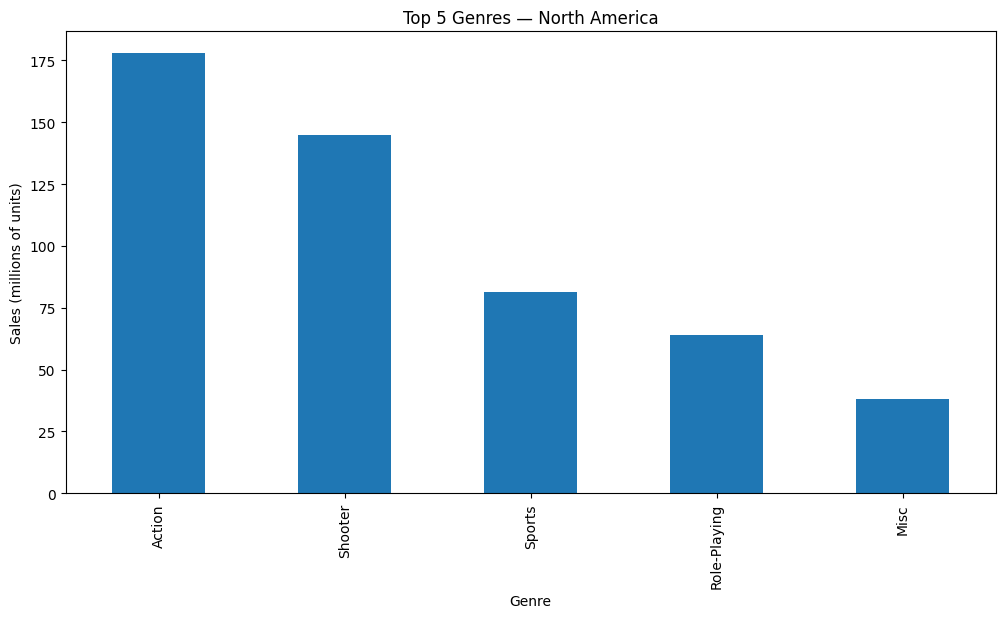

In [35]:
na_genre = games_recent.groupby('genre')['na_sales'].sum().sort_values(ascending=False)

na_genre.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Genres — North America')
plt.xlabel('Genre')
plt.ylabel('Sales (millions of units)')

plt.show()

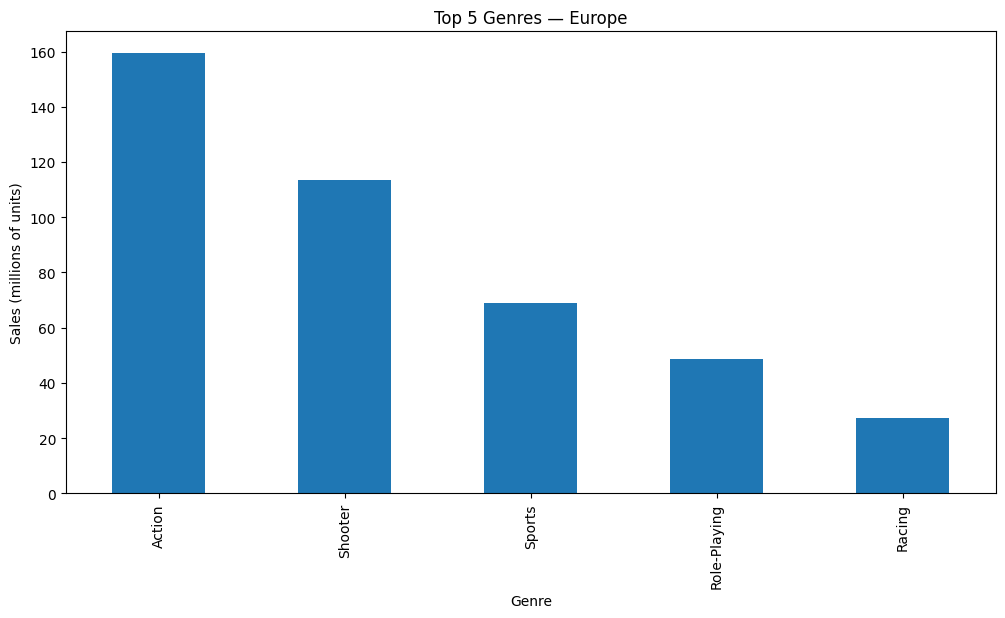

In [36]:
eu_genre = games_recent.groupby('genre')['eu_sales'].sum().sort_values(ascending=False)

eu_genre.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Genres — Europe')
plt.xlabel('Genre')
plt.ylabel('Sales (millions of units)')

plt.show()

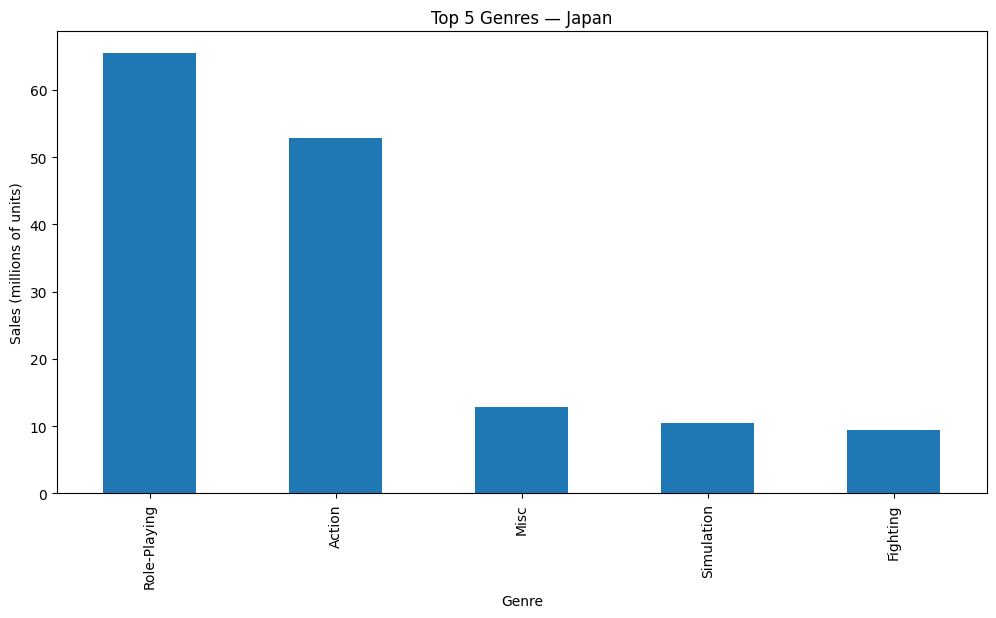

In [37]:
jp_genre = games_recent.groupby('genre')['jp_sales'].sum().sort_values(ascending=False)

jp_genre.head().plot(kind='bar', figsize=(12,6))

plt.title('Top 5 Genres — Japan')
plt.xlabel('Genre')
plt.ylabel('Sales (millions of units)')

plt.show()

- Genre preferences also vary across regions.
- Action and Shooter lead in North America and Europe, followed by Sports, indicating broadly similar preferences in these markets.
- Japan differs: Role-Playing games lead by a substantial margin, followed by Action.
- Simulation and Fighting also rank among Japan's top five genres.
- These patterns suggest that North American and European audiences favor Action, Shooter, and Sports, while Role-Playing games have greater relative importance in Japan.

### ESRB Ratings by Region

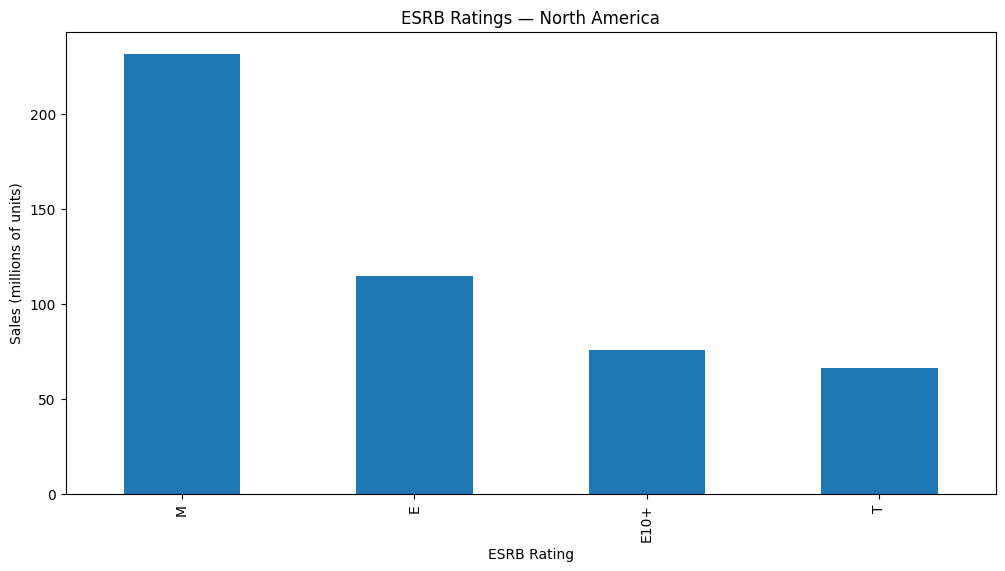

In [38]:
na_rating = games_recent.groupby('rating')['na_sales'].sum().sort_values(ascending=False)

na_rating.plot(kind='bar', figsize=(12,6))

plt.title('ESRB Ratings — North America')
plt.xlabel('ESRB Rating')
plt.ylabel('Sales (millions of units)')

plt.show()

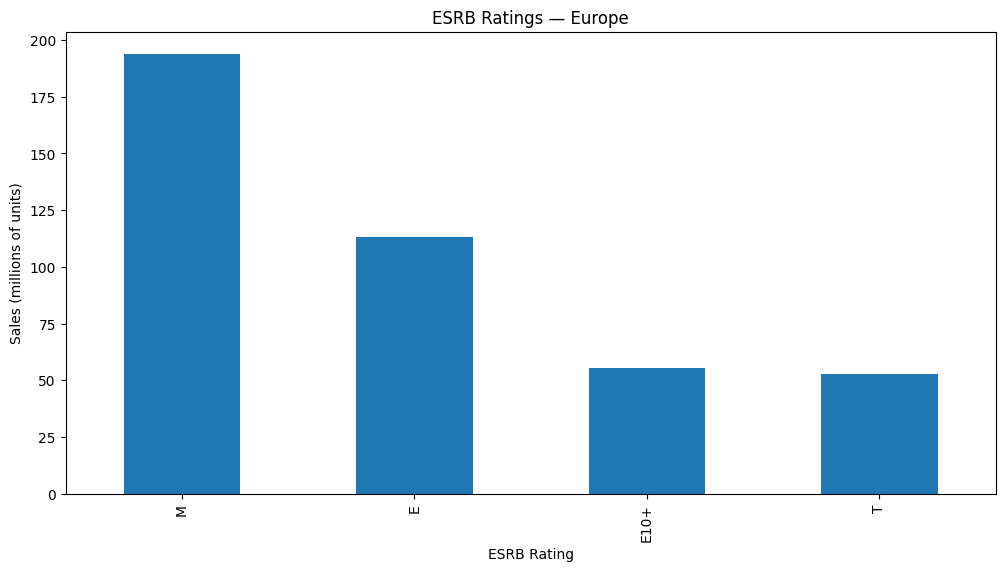

In [39]:
eu_rating = games_recent.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)

eu_rating.plot(kind='bar', figsize=(12,6))

plt.title('ESRB Ratings — Europe')
plt.xlabel('ESRB Rating')
plt.ylabel('Sales (millions of units)')

plt.show()

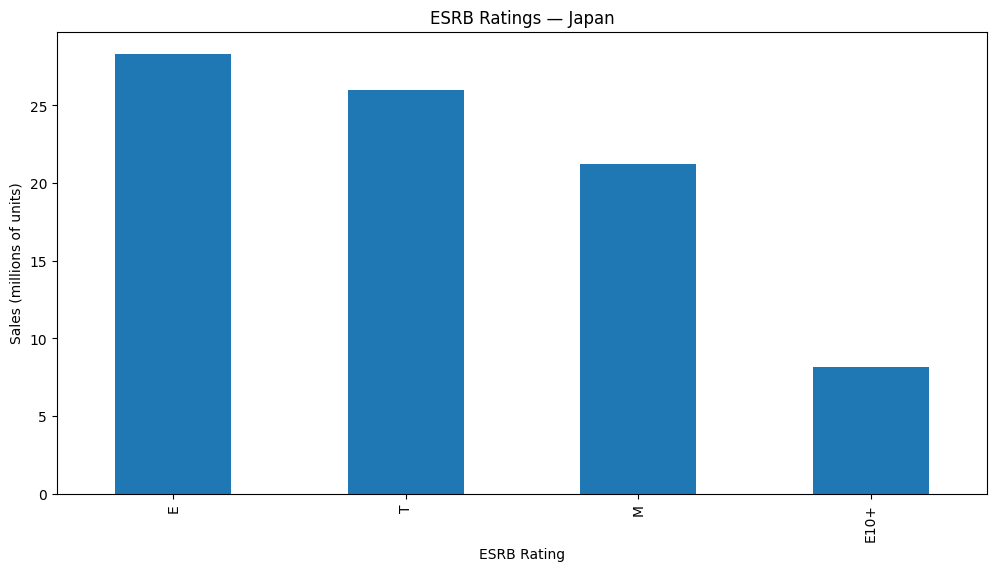

In [40]:
jp_rating = games_recent.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)

jp_rating.plot(kind='bar', figsize=(12,6))

plt.title('ESRB Ratings — Japan')
plt.xlabel('ESRB Rating')
plt.ylabel('Sales (millions of units)')

plt.show()

- Sales by ESRB category follow different patterns across the regions in this dataset.
- In North America and Europe, M (Mature) games generate the highest sales, followed by E (Everyone).
- In Japan, E (Everyone) leads, followed by T (Teen) and M (Mature).
- This suggests a stronger sales concentration in Mature-rated games in North America and Europe, while Japan has a more balanced distribution across age-rating categories. Note that missing ESRB ratings and differences in regional rating systems limit interpretation.

## Statistical Hypothesis Testing

### Xbox One vs. PC User Scores

**Null hypothesis (H₀):** Mean user ratings for Xbox One and PC games are equal.

**Alternative hypothesis (H₁):** Mean user ratings for Xbox One and PC games differ.

We use a significance level of **α = 0.05**, corresponding to a 5% Type I error rate if the null hypothesis is true. A two-sided Welch's t-test is used to compare the two means.

In [41]:
xone = games_recent[(games_recent['platform'] == 'XOne') & (games_recent['user_score'].notna())]['user_score']

pc = games_recent[(games_recent['platform'] == 'PC') & (games_recent['user_score'].notna())]['user_score']

In [42]:
results = ttest_ind(xone, pc, equal_var=False)

print('p-value:', results.pvalue)

p-value: 0.5489537965134912


In [43]:
alpha = 0.05

if results.pvalue < alpha:
    print('Reject the null hypothesis.')
else:
    print('Fail to reject the null hypothesis.')

Fail to reject the null hypothesis.


- The test does not provide sufficient statistical evidence to conclude that mean user ratings differ between Xbox One and PC games.
- This does **not** prove that the two population means are equal; we simply fail to reject the null hypothesis at the chosen significance level.

### Action vs. Sports User Scores

**Null hypothesis (H₀):** Mean user ratings for Action and Sports games are equal.

**Alternative hypothesis (H₁):** Mean user ratings for Action and Sports games differ.

We use the same two-sided Welch's t-test and significance level (α = 0.05).

In [44]:
action = games_recent[(games_recent['genre'] == 'Action') & (games_recent['user_score'].notna())]['user_score']

sports = games_recent[(games_recent['genre'] == 'Sports') & (games_recent['user_score'].notna())]['user_score']

In [45]:
results = ttest_ind(action, sports, equal_var=False)

print('p-value:', results.pvalue)

p-value: 4.243077765726399e-20


In [46]:
alpha = 0.05

if results.pvalue < alpha:
    print('Reject the null hypothesis.')
else:
    print('Fail to reject the null hypothesis.')

Reject the null hypothesis.


- The test indicates a statistically significant difference between mean user ratings for Action and Sports games.
- The result suggests that these genres receive different average user ratings within the analyzed dataset; it does not establish what causes the difference.

## Overall Conclusion

The dataset was prepared by standardizing column names, converting data types, handling missing values, and calculating `total_sales` to support the analysis.

- **Market history:** Game releases grew strongly through 2008–2009 before declining in the available data.
- **Platform lifecycles:** Major platforms generally remain commercially relevant for around 8–10 years in this sample, supporting the use of more recent data for the hypothetical 2017 campaign.
- **Platforms:** PS4 and Xbox One look most promising for near-term campaigns, while PS3 and Xbox 360 are experiencing declining sales.
- **Genres:** Action, Shooter, Role-Playing, and Sports account for the greatest total sales.
- **Reviews:** Critic scores are moderately positively correlated with PS4 sales, whereas user scores show little linear relationship with sales.
- **Regional differences:** North America and Europe share several preferences, while Japan has a distinctive market profile with stronger representation of Nintendo handhelds and Role-Playing games.
- **Hypothesis tests:** The analysis finds no statistically significant difference in mean user ratings between Xbox One and PC games, but does find a significant difference between Action and Sports games.

**Business takeaway:** Platform, genre, geography, and critic reviews can help guide a targeted marketing strategy for the hypothetical 2017 launch season. These findings are based on historical observational data; they should not be interpreted as causal relationships or predictions for today's market.